<a href="https://colab.research.google.com/github/Devansh070/BTP/blob/main/contact_angle_models_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Contact angle prediction from epsilon, time and trajectory-derived water flux features

In [1]:
import os
import re
import sys
import glob
import subprocess

try:
    import mdtraj
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mdtraj"], check=True)
    import mdtraj

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def inputs_present():
    return len(glob.glob("*trajectory_alignment*.csv")) >= 1 and len(glob.glob("*.xtc")) >= 5


if IN_COLAB and not inputs_present():
    print("select the csv and all five xtc files")
    files.upload()

print("csv:", glob.glob("*.csv"))
print("xtc:", sorted(glob.glob("*.xtc")))

csv: ['contact_angle_trajectory_alignment.csv']
xtc: ['water_50ps_0.005.xtc', 'water_50ps_0.05.xtc', 'water_50ps_0.25.xtc', 'water_50ps_0.7.xtc', 'water_50ps_1.3.xtc']


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

warnings.filterwarnings("ignore")

SEED = 42
CSV_PATH = os.environ.get("CSV_PATH", (glob.glob("*trajectory_alignment*.csv") or ["contact_angle_trajectory_alignment.csv"])[0])
TRAJ_DIR = os.environ.get("TRAJ_DIR", os.path.dirname(os.path.abspath(CSV_PATH)))
TOPOLOGY_PATH = os.environ.get("TOPOLOGY_PATH", "")
OUT_DIR = os.environ.get("OUT_DIR", "outputs")
OXYGEN_STRIDE = 3
OXYGEN_OFFSET = 0
CV_RADIUS_NM = 2.0
CV_HEIGHT_NM = 1.0
TRAIN_TMAX_PS = 750
TRAJ_COLS = ["n_cv", "n_enter", "n_leave", "net_flux", "cum_enter", "cum_leave",
             "com_z", "height", "r_base", "rg", "cap_angle_est"]

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
if HAS_TORCH:
    torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("torch available:", HAS_TORCH)

torch available: True


## Load data and fill missing frames

In [3]:
raw = pd.read_csv(CSV_PATH).sort_values(["epsilon", "time_ps"]).reset_index(drop=True)


def fill_missing_frames(frame):
    parts = []
    for eps, g in frame.groupby("epsilon", sort=True):
        g = g.sort_values("time_ps").copy()
        g["source_time_ps"] = g["time_ps"]
        g["is_copied"] = False
        available = g[g["trajectory_frame_available"]]
        missing = ~g["trajectory_frame_available"]
        if missing.any() and len(available) > 0:
            last = available.iloc[-1]
            g.loc[missing, "contact_angle_deg"] = last["contact_angle_deg"]
            g.loc[missing, "source_time_ps"] = last["time_ps"]
            g.loc[missing, "is_copied"] = True
        parts.append(g)
    return pd.concat(parts, ignore_index=True)


df = fill_missing_frames(raw)
EPS_LIST = sorted(df["epsilon"].unique())
summary = df.groupby("epsilon").agg(
    total_frames=("time_ps", "size"),
    real_frames=("is_copied", lambda s: int((~s).sum())),
    copied_frames=("is_copied", "sum"),
)
display(summary)
display(df[df["epsilon"] == EPS_LIST[0]][["epsilon", "time_ps", "contact_angle_deg", "is_copied", "source_time_ps"]].head(6))

,total_frames,real_frames,copied_frames
epsilon,,,
0.005,20,2,18
0.050,20,20,0
0.250,20,20,0
0.700,20,20,0
1.300,20,20,0


,epsilon,time_ps,contact_angle_deg,is_copied,source_time_ps
0,0.005,50,134.185,False,50
1,0.005,100,137.644,False,100
2,0.005,150,137.644,True,100
3,0.005,200,137.644,True,100
4,0.005,250,137.644,True,100
5,0.005,300,137.644,True,100


## Trajectory features (water molecules entering or leaving the control volume)

In [4]:
def oxygen_indices(n_atoms):
    if TOPOLOGY_PATH and os.path.exists(TOPOLOGY_PATH):
        import mdtraj
        top = mdtraj.load(TOPOLOGY_PATH).topology
        idx = top.select("water and (name O or name OW)")
        if len(idx) > 0:
            return np.asarray(idx)
    return np.arange(OXYGEN_OFFSET, n_atoms, OXYGEN_STRIDE)


def load_oxygen_frames(path):
    from mdtraj.formats import XTCTrajectoryFile
    with XTCTrajectoryFile(path) as f:
        xyz, times, steps, box = f.read()
    ox = oxygen_indices(xyz.shape[1])
    return xyz[:, ox, :].astype(np.float64), np.asarray(times, dtype=float)


def pick_index(times, time_ps, frame_number):
    j = int(np.argmin(np.abs(times - time_ps)))
    if abs(times[j] - time_ps) <= 1e-3 * max(1.0, time_ps):
        return j
    k = int(frame_number)
    return min(k, len(times) - 1)


def find_traj_file(eps, listed_name):
    tag = re.escape(format(float(eps), "g")).replace(r"\.", "[._]")
    pattern = re.compile(r"water_50ps_" + tag + r"(?:\s*\(\d+\))?\.xtc$")
    for name in sorted(os.listdir(TRAJ_DIR)):
        if pattern.search(name):
            return os.path.join(TRAJ_DIR, name)
    cand = os.path.join(TRAJ_DIR, listed_name)
    if os.path.exists(cand):
        return cand
    raise FileNotFoundError(f"no xtc file found for epsilon={eps} in {TRAJ_DIR}")


def traj_features_for_eps(eps, g):
    path = find_traj_file(eps, g["trajectory_file"].iloc[0])
    oxy, times = load_oxygen_frames(path)
    real = g[~g["is_copied"]].sort_values("time_ps")
    idxs = [pick_index(times, t, fn) for t, fn in zip(real["time_ps"], real["trajectory_frame_number"])]
    frames = [oxy[i] for i in idxs]
    z_surf = np.percentile(frames[0][:, 2], 1)
    center = frames[0][:, :2].mean(axis=0)
    rows = []
    prev = None
    cum_in = 0
    cum_out = 0
    for fr in frames:
        d = np.linalg.norm(fr[:, :2] - center, axis=1)
        inside = (d <= CV_RADIUS_NM) & (fr[:, 2] >= z_surf) & (fr[:, 2] <= z_surf + CV_HEIGHT_NM)
        if prev is None:
            n_in = 0
            n_out = 0
        else:
            n_in = int((inside & ~prev).sum())
            n_out = int((~inside & prev).sum())
        cum_in += n_in
        cum_out += n_out
        prev = inside
        z = fr[:, 2] - z_surf
        com = fr.mean(axis=0)
        xy = np.linalg.norm(fr[:, :2] - com[:2], axis=1)
        base = z <= 0.5
        r_base = np.percentile(xy[base], 95) if base.sum() >= 3 else np.percentile(xy, 95)
        height = np.percentile(z, 99)
        rg = np.sqrt(((fr - com) ** 2).sum(axis=1).mean())
        rows.append({
            "n_cv": int(inside.sum()), "n_enter": n_in, "n_leave": n_out, "net_flux": n_in - n_out,
            "cum_enter": cum_in, "cum_leave": cum_out, "com_z": z.mean(), "height": height,
            "r_base": r_base, "rg": rg,
            "cap_angle_est": 2.0 * np.degrees(np.arctan2(height, max(r_base, 1e-6))),
        })
    return pd.DataFrame(rows)


def attach_traj(frame):
    parts = []
    for eps, g in frame.groupby("epsilon", sort=True):
        g = g.sort_values("time_ps").reset_index(drop=True)
        tf = traj_features_for_eps(eps, g)
        for c in TRAJ_COLS:
            g[c] = np.nan
        real_mask = ~g["is_copied"].values
        g.loc[real_mask, TRAJ_COLS] = tf[TRAJ_COLS].values
        last = tf[TRAJ_COLS].iloc[-1]
        for c in TRAJ_COLS:
            g.loc[g["is_copied"], c] = last[c]
        parts.append(g)
    return pd.concat(parts, ignore_index=True)


try:
    df = attach_traj(df)
    USE_TRAJ = True
    df.to_csv(os.path.join(OUT_DIR, "trajectory_features.csv"), index=False)
    print("trajectory features extracted from xtc files")
except Exception as exc:
    USE_TRAJ = False
    print("trajectory features unavailable, using epsilon and time only:", repr(exc))

trajectory features extracted from xtc files


## Feature engineering

In [5]:
df["log_eps"] = np.log10(df["epsilon"])
df["log_time"] = np.log10(df["time_ps"])
BASE_COLS = ["epsilon", "log_eps", "time_ps", "log_time"]
FEATURES = BASE_COLS + (TRAJ_COLS if USE_TRAJ else [])
PHYS_COLS = [FEATURES.index("log_eps"), FEATURES.index("time_ps")] + \
            [FEATURES.index(c) for c in TRAJ_COLS if c in FEATURES]
TARGET = "contact_angle_deg"
print(len(df), "rows |", len(FEATURES), "features:", FEATURES)

100 rows | 15 features: ['epsilon', 'log_eps', 'time_ps', 'log_time', 'n_cv', 'n_enter', 'n_leave', 'net_flux', 'cum_enter', 'cum_leave', 'com_z', 'height', 'r_base', 'rg', 'cap_angle_est']


## Data overview

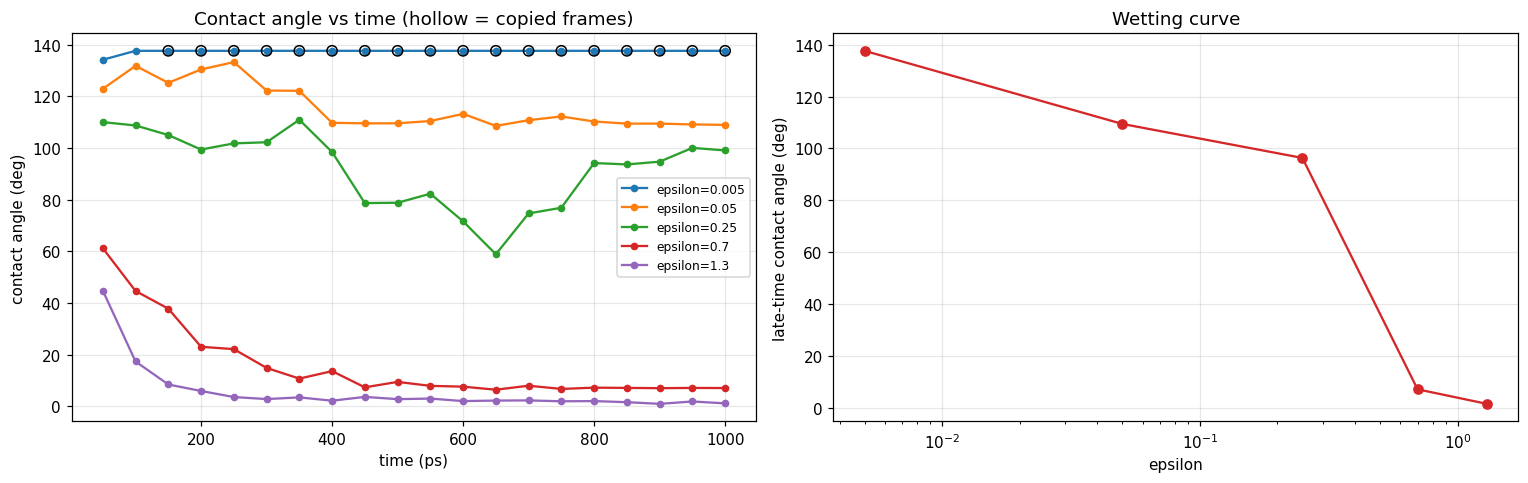

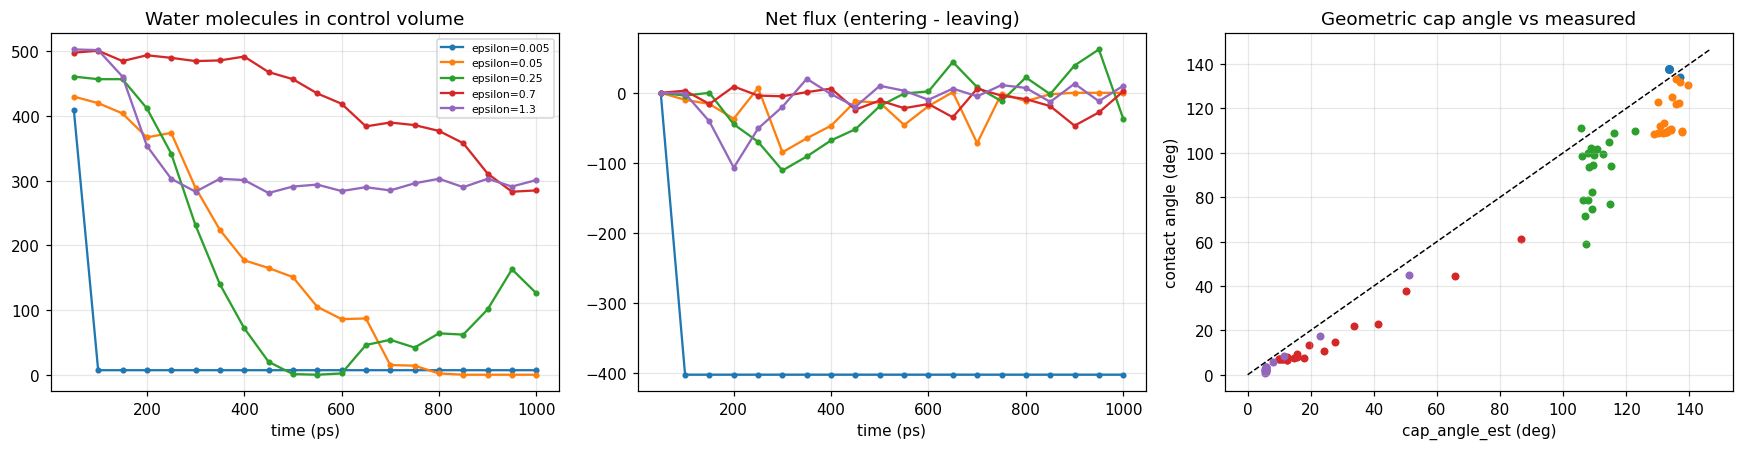

In [6]:
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, e in enumerate(EPS_LIST):
    g = df[df["epsilon"] == e]
    ax[0].plot(g["time_ps"], g[TARGET], "-o", color=cmap(i), ms=4, label=f"epsilon={e}")
    c = g[g["is_copied"]]
    ax[0].scatter(c["time_ps"], c[TARGET], facecolors="none", edgecolors="k", s=45, zorder=3)
ax[0].set_xlabel("time (ps)")
ax[0].set_ylabel("contact angle (deg)")
ax[0].set_title("Contact angle vs time (hollow = copied frames)")
ax[0].legend(fontsize=8)
eq = [df[df["epsilon"] == e].sort_values("time_ps").tail(5)[TARGET].mean() for e in EPS_LIST]
ax[1].semilogx(EPS_LIST, eq, "-o", color="tab:red")
ax[1].set_xlabel("epsilon")
ax[1].set_ylabel("late-time contact angle (deg)")
ax[1].set_title("Wetting curve")
plt.tight_layout()
plt.show()

if USE_TRAJ:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for i, e in enumerate(EPS_LIST):
        g = df[df["epsilon"] == e]
        ax[0].plot(g["time_ps"], g["n_cv"], "-o", ms=3, color=cmap(i), label=f"epsilon={e}")
        ax[1].plot(g["time_ps"], g["net_flux"], "-o", ms=3, color=cmap(i))
        ax[2].scatter(g["cap_angle_est"], g[TARGET], color=cmap(i), s=18)
    ax[0].set_title("Water molecules in control volume")
    ax[0].set_xlabel("time (ps)")
    ax[0].legend(fontsize=7)
    ax[1].set_title("Net flux (entering - leaving)")
    ax[1].set_xlabel("time (ps)")
    lim = [0, max(df["cap_angle_est"].max(), df[TARGET].max()) * 1.05]
    ax[2].plot(lim, lim, "k--", lw=1)
    ax[2].set_title("Geometric cap angle vs measured")
    ax[2].set_xlabel("cap_angle_est (deg)")
    ax[2].set_ylabel("contact angle (deg)")
    plt.tight_layout()
    plt.show()

## Models

In [7]:
def build_net(in_dim, hidden, depth):
    layers = []
    d = in_dim
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.SiLU()]
        d = hidden
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)


if HAS_TORCH:
    class TorchMLP(BaseEstimator, RegressorMixin):
        def __init__(self, hidden=64, depth=3, epochs=2000, lr=3e-3, wd=1e-4, n_models=3, seed=SEED):
            self.hidden = hidden
            self.depth = depth
            self.epochs = epochs
            self.lr = lr
            self.wd = wd
            self.n_models = n_models
            self.seed = seed

        def fit(self, X, y):
            X = np.asarray(X, dtype=float)
            y = np.asarray(y, dtype=float)
            self.sx_ = StandardScaler().fit(X)
            Xs = torch.tensor(self.sx_.transform(X), dtype=torch.float32)
            yt = torch.tensor(y / 180.0, dtype=torch.float32).unsqueeze(1)
            self.nets_ = []
            for m in range(self.n_models):
                torch.manual_seed(self.seed + m)
                net = build_net(Xs.shape[1], self.hidden, self.depth)
                opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
                sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.epochs)
                for _ in range(self.epochs):
                    opt.zero_grad()
                    loss = ((net(Xs) - yt) ** 2).mean()
                    loss.backward()
                    opt.step()
                    sched.step()
                net.eval()
                self.nets_.append(net)
            return self

        def predict(self, X):
            Xs = torch.tensor(self.sx_.transform(np.asarray(X, dtype=float)), dtype=torch.float32)
            with torch.no_grad():
                out = np.mean([n(Xs).squeeze(1).numpy() for n in self.nets_], axis=0)
            return np.clip(out * 180.0, 0.0, 180.0)


    class PhysicsNN(BaseEstimator, RegressorMixin):
        def __init__(self, cols=None, hidden=64, depth=3, epochs=1500, lr=3e-3, wd=1e-4, n_models=3,
                     w_cos=0.5, w_mono=1.0, w_time=0.01, jitter=0.35, seed=SEED):
            self.cols = cols
            self.hidden = hidden
            self.depth = depth
            self.epochs = epochs
            self.lr = lr
            self.wd = wd
            self.n_models = n_models
            self.w_cos = w_cos
            self.w_mono = w_mono
            self.w_time = w_time
            self.jitter = jitter
            self.seed = seed

        def fit(self, X, y):
            X = np.asarray(X, dtype=float)[:, self.cols]
            y = np.asarray(y, dtype=float) / 180.0
            self.sx_ = StandardScaler().fit(X)
            Xs = torch.tensor(self.sx_.transform(X), dtype=torch.float32)
            yt = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
            tmax = max(float(X[:, 1].max()), 1e-9)
            w = np.clip((X[:, 1] / tmax - 0.5) * 2.0, 0.0, 1.0)
            wt = torch.tensor(np.concatenate([w, w]), dtype=torch.float32)
            self.nets_ = []
            for m in range(self.n_models):
                torch.manual_seed(self.seed + m)
                net = build_net(Xs.shape[1], self.hidden, self.depth)
                opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
                sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.epochs)
                for _ in range(self.epochs):
                    opt.zero_grad()
                    p = torch.sigmoid(net(Xs))
                    data = ((p - yt) ** 2).mean() + self.w_cos * ((torch.cos(np.pi * p) - torch.cos(np.pi * yt)) ** 2).mean()
                    xj = Xs.clone()
                    xj[:, 0] = xj[:, 0] + self.jitter * torch.randn(xj.shape[0])
                    xa = torch.cat([Xs, xj], dim=0).requires_grad_(True)
                    pa = torch.sigmoid(net(xa))
                    g = torch.autograd.grad(pa.sum(), xa, create_graph=True)[0]
                    mono = (torch.relu(g[:, 0]) ** 2).mean()
                    late = (wt * g[:, 1] ** 2).mean()
                    loss = data + self.w_mono * mono + self.w_time * late
                    loss.backward()
                    opt.step()
                    sched.step()
                net.eval()
                self.nets_.append(net)
            return self

        def predict(self, X):
            X = np.asarray(X, dtype=float)[:, self.cols]
            Xs = torch.tensor(self.sx_.transform(X), dtype=torch.float32)
            with torch.no_grad():
                out = np.mean([torch.sigmoid(n(Xs)).squeeze(1).numpy() for n in self.nets_], axis=0)
            return out * 180.0


def scaled_target(reg):
    return TransformedTargetRegressor(regressor=reg, transformer=StandardScaler())


def poly_ridge(alpha, degree=3):
    nf = len(FEATURES)
    base_idx = list(range(len(BASE_COLS)))
    rest_idx = list(range(len(BASE_COLS), nf))
    parts = [("poly", make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False)), base_idx)]
    if rest_idx:
        parts.append(("rest", StandardScaler(), rest_idx))
    return make_pipeline(ColumnTransformer(parts), Ridge(alpha=alpha))


def make_models():
    models = {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Polynomial Ridge": poly_ridge(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=500, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                                       subsample=0.9, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.9,
                                colsample_bytree=0.9, reg_lambda=1.0, random_state=SEED, n_jobs=-1),
        "SVR": scaled_target(make_pipeline(StandardScaler(), SVR(C=20.0, epsilon=0.02, gamma="scale"))),
        "Gaussian Process": scaled_target(make_pipeline(StandardScaler(), GaussianProcessRegressor(
            kernel=ConstantKernel(1.0) * RBF(length_scale=2.0) + WhiteKernel(1e-3),
            n_restarts_optimizer=3, random_state=SEED))),
        "MLP (sklearn)": scaled_target(make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 64), activation="tanh", solver="lbfgs", alpha=1e-3,
            max_iter=5000, random_state=SEED))),
    }
    if HAS_TORCH:
        models["Neural Network (PyTorch)"] = TorchMLP()
        models["Physics-Constrained NN"] = PhysicsNN(cols=PHYS_COLS)
    return models


MODELS = make_models()
ENSEMBLE_MEMBERS = [m for m in ["XGBoost", "Gaussian Process", "SVR", "Extra Trees",
                                "Neural Network (PyTorch)", "Physics-Constrained NN"] if m in MODELS]
print(list(MODELS))
print("ensemble members:", ENSEMBLE_MEMBERS)

['Linear Regression', 'Ridge', 'Polynomial Ridge', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'SVR', 'Gaussian Process', 'MLP (sklearn)', 'Neural Network (PyTorch)', 'Physics-Constrained NN']
ensemble members: ['XGBoost', 'Gaussian Process', 'SVR', 'Extra Trees', 'Neural Network (PyTorch)', 'Physics-Constrained NN']


## Evaluation utilities

In [8]:
def metrics(y, p):
    p = np.clip(p, 0.0, 180.0)
    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "R2": r2_score(y, p),
        "MaxAE": float(np.max(np.abs(y - p))),
    }


def run_protocol(frame, splits, models):
    out = []
    for sid, (tr, te) in enumerate(splits):
        Xtr = frame.loc[tr, FEATURES].values
        ytr = frame.loc[tr, TARGET].values
        Xte = frame.loc[te, FEATURES].values
        for name, mdl in models.items():
            est = clone(mdl).fit(Xtr, ytr)
            pred = np.clip(est.predict(Xte), 0.0, 180.0)
            out.append(pd.DataFrame({
                "model": name, "split": sid,
                "epsilon": frame.loc[te, "epsilon"].values,
                "time_ps": frame.loc[te, "time_ps"].values,
                "y": frame.loc[te, TARGET].values, "pred": pred,
            }))
        print(f"split {sid + 1}/{len(splits)} done")
    res = pd.concat(out, ignore_index=True)
    ens = (res[res["model"].isin(ENSEMBLE_MEMBERS)]
           .groupby(["split", "epsilon", "time_ps", "y"], as_index=False)["pred"].mean())
    ens["model"] = "Ensemble (avg)"
    return pd.concat([res, ens], ignore_index=True)


def score_table(res):
    rows = [{"model": name, **metrics(g["y"].values, g["pred"].values)} for name, g in res.groupby("model")]
    return pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)

## Protocol A: temporal holdout (train t <= 750 ps, test t > 750 ps, real frames only)

In [9]:
real_mask = ~df["is_copied"].values
tr_idx = np.where(df["time_ps"].values <= TRAIN_TMAX_PS)[0]
te_idx = np.where((df["time_ps"].values > TRAIN_TMAX_PS) & real_mask)[0]
res_A = run_protocol(df, [(tr_idx, te_idx)], MODELS)
table_A = score_table(res_A)
print(f"train rows: {len(tr_idx)} | test rows: {len(te_idx)}")
display(table_A.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}", "MaxAE": "{:.3f}"}))
table_A.to_csv(os.path.join(OUT_DIR, "metrics_temporal_holdout.csv"), index=False)
res_A.to_csv(os.path.join(OUT_DIR, "predictions_temporal_holdout.csv"), index=False)

split 1/1 done
train rows: 75 | test rows: 20


,model,MAE,RMSE,R2,MaxAE
0,XGBoost,5.714,8.219,0.9725,18.997
1,Ensemble (avg),5.355,8.663,0.9695,24.004
2,Random Forest,5.441,8.749,0.9689,24.075
3,Physics-Constrained NN,6.953,9.075,0.9665,20.447
4,SVR,7.331,9.307,0.9648,22.176
5,Ridge,7.018,9.556,0.9628,22.987
6,Gradient Boosting,5.867,9.909,0.9601,27.129
7,Polynomial Ridge,8.245,10.000,0.9593,18.021
8,Extra Trees,5.818,10.128,0.9583,27.427
9,Linear Regression,7.941,10.657,0.9538,29.052


## Protocol B: leave-one-epsilon-out (train on the other epsilons, test on the held-out epsilon)

In [10]:
splits_B = [(np.where(df["epsilon"].values != e)[0],
             np.where((df["epsilon"].values == e) & real_mask)[0]) for e in EPS_LIST]
res_B = run_protocol(df, splits_B, MODELS)
interior = EPS_LIST[1:-1]
table_B_all = score_table(res_B)
table_B_int = score_table(res_B[res_B["epsilon"].isin(interior)])
print("pooled over all held-out epsilons (includes the two extrapolation ends)")
display(table_B_all.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}", "MaxAE": "{:.3f}"}))
print(f"interior epsilons only {interior}")
display(table_B_int.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}", "MaxAE": "{:.3f}"}))
per_eps = (res_B.assign(abs_err=(res_B["y"] - res_B["pred"]).abs())
           .pivot_table(index="model", columns="epsilon", values="abs_err", aggfunc="mean")
           .round(2))
print("MAE per held-out epsilon")
display(per_eps)
table_B_all.to_csv(os.path.join(OUT_DIR, "metrics_leave_one_epsilon_out_all.csv"), index=False)
table_B_int.to_csv(os.path.join(OUT_DIR, "metrics_leave_one_epsilon_out_interior.csv"), index=False)
res_B.to_csv(os.path.join(OUT_DIR, "predictions_leave_one_epsilon_out.csv"), index=False)

split 1/5 done
split 2/5 done
split 3/5 done
split 4/5 done
split 5/5 done
pooled over all held-out epsilons (includes the two extrapolation ends)


,model,MAE,RMSE,R2,MaxAE
0,Random Forest,8.686,10.477,0.9560,30.447
1,Extra Trees,10.468,11.870,0.9435,29.421
2,Gradient Boosting,12.123,14.031,0.9210,31.191
3,Ridge,14.474,20.305,0.8346,43.898
4,Gaussian Process,14.738,21.506,0.8144,75.788
5,Ensemble (avg),18.472,26.035,0.7280,71.411
6,Polynomial Ridge,19.355,29.257,0.6565,68.797
7,Neural Network (PyTorch),20.734,29.771,0.6444,130.601
8,SVR,25.583,32.241,0.5829,80.061
9,Linear Regression,25.020,37.347,0.4403,80.605


interior epsilons only [np.float64(0.05), np.float64(0.25), np.float64(0.7)]


,model,MAE,RMSE,R2,MaxAE
0,Random Forest,8.971,11.119,0.9378,30.447
1,Extra Trees,11.531,12.978,0.9152,29.421
2,Gradient Boosting,13.671,15.447,0.8799,31.191
3,Ridge,17.099,22.192,0.7521,42.066
4,SVR,17.273,22.426,0.7468,44.654
5,Gaussian Process,17.219,22.781,0.7388,45.298
6,Ensemble (avg),20.235,28.258,0.5980,60.086
7,Neural Network (PyTorch),24.135,29.734,0.5550,60.579
8,Polynomial Ridge,23.652,33.144,0.4470,68.797
9,Linear Regression,31.052,42.582,0.0873,80.605


MAE per held-out epsilon


epsilon,0.005,0.050,0.250,0.700,1.300
model,,,,,
Ensemble (avg),41.27,6.69,9.84,44.17,10.90
Extra Trees,13.77,8.68,10.89,15.02,6.95
Gaussian Process,41.99,6.66,11.76,33.23,4.57
Gradient Boosting,17.55,9.76,11.72,19.53,6.94
Linear Regression,37.40,9.64,14.66,68.86,5.68
MLP (sklearn),26.23,32.43,17.00,57.38,4.21
Neural Network (PyTorch),69.17,17.35,12.29,42.77,5.68
Physics-Constrained NN,54.03,18.13,11.78,72.96,4.50
Polynomial Ridge,27.15,5.14,11.89,53.92,5.68


## Plots

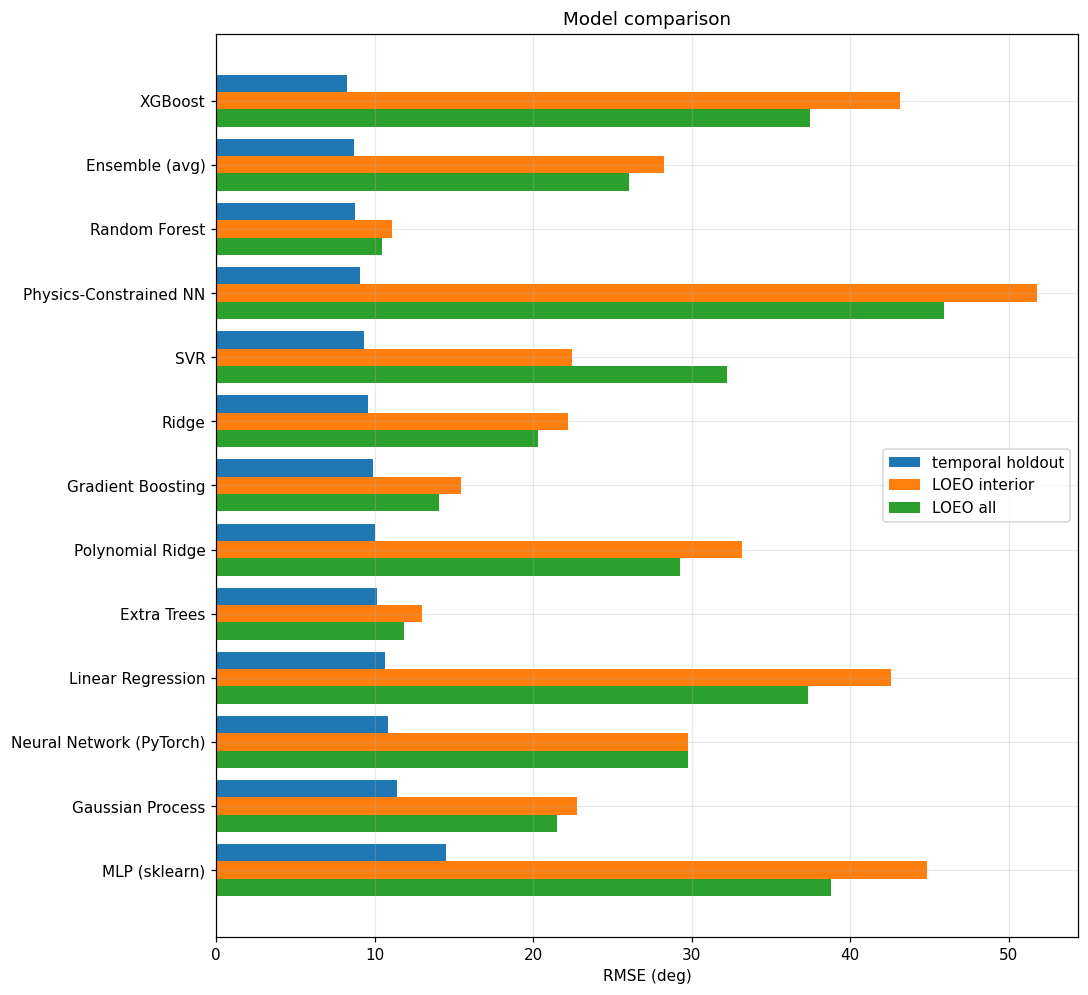

In [11]:
cmp = table_A[["model", "RMSE"]].merge(table_B_int[["model", "RMSE"]], on="model", suffixes=("_temporal", "_LOEO_interior"))
cmp = cmp.merge(table_B_all[["model", "RMSE"]].rename(columns={"RMSE": "RMSE_LOEO_all"}), on="model")
cmp = cmp.sort_values("RMSE_temporal")
y = np.arange(len(cmp))
fig, ax = plt.subplots(figsize=(10, 0.55 * len(cmp) + 2))
ax.barh(y - 0.27, cmp["RMSE_temporal"], 0.27, label="temporal holdout")
ax.barh(y, cmp["RMSE_LOEO_interior"], 0.27, label="LOEO interior")
ax.barh(y + 0.27, cmp["RMSE_LOEO_all"], 0.27, label="LOEO all")
ax.set_yticks(y)
ax.set_yticklabels(cmp["model"])
ax.invert_yaxis()
ax.set_xlabel("RMSE (deg)")
ax.set_title("Model comparison")
ax.legend()
plt.tight_layout()
plt.show()

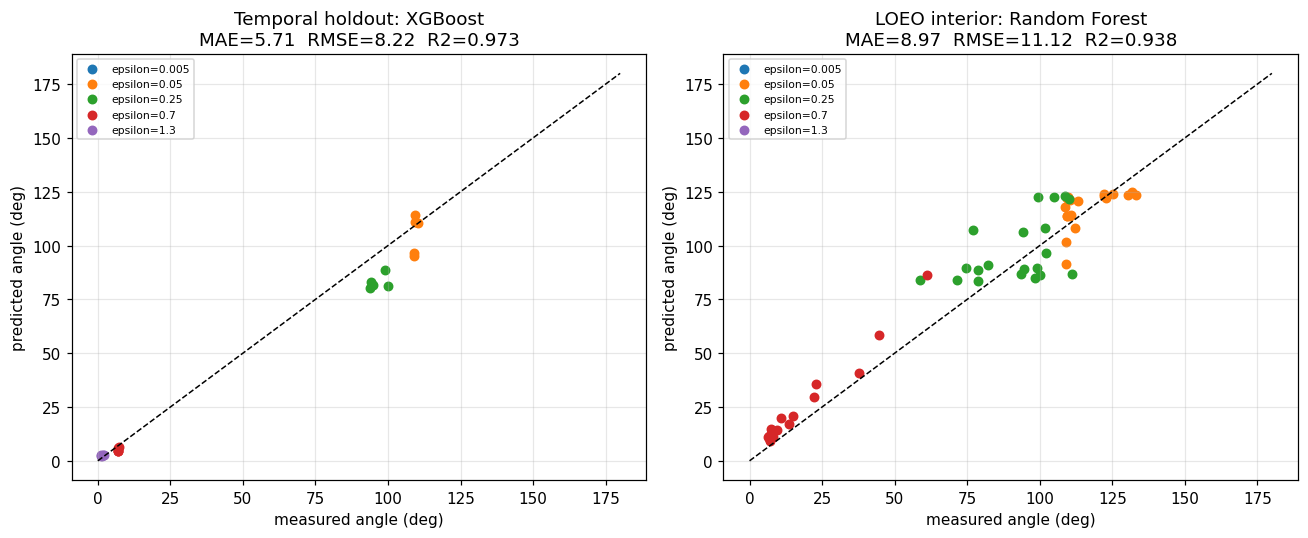

In [12]:
best_A = table_A.iloc[0]["model"]
best_B = table_B_int.iloc[0]["model"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, res, name, title in [(ax[0], res_A, best_A, "Temporal holdout"),
                            (ax[1], res_B[res_B["epsilon"].isin(interior)], best_B, "LOEO interior")]:
    g = res[res["model"] == name]
    for i, e in enumerate(EPS_LIST):
        s = g[g["epsilon"] == e]
        a.scatter(s["y"], s["pred"], color=cmap(i), s=30, label=f"epsilon={e}")
    lim = [0, 180]
    a.plot(lim, lim, "k--", lw=1)
    m = metrics(g["y"].values, g["pred"].values)
    a.set_title(f"{title}: {name}\nMAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}  R2={m['R2']:.3f}")
    a.set_xlabel("measured angle (deg)")
    a.set_ylabel("predicted angle (deg)")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

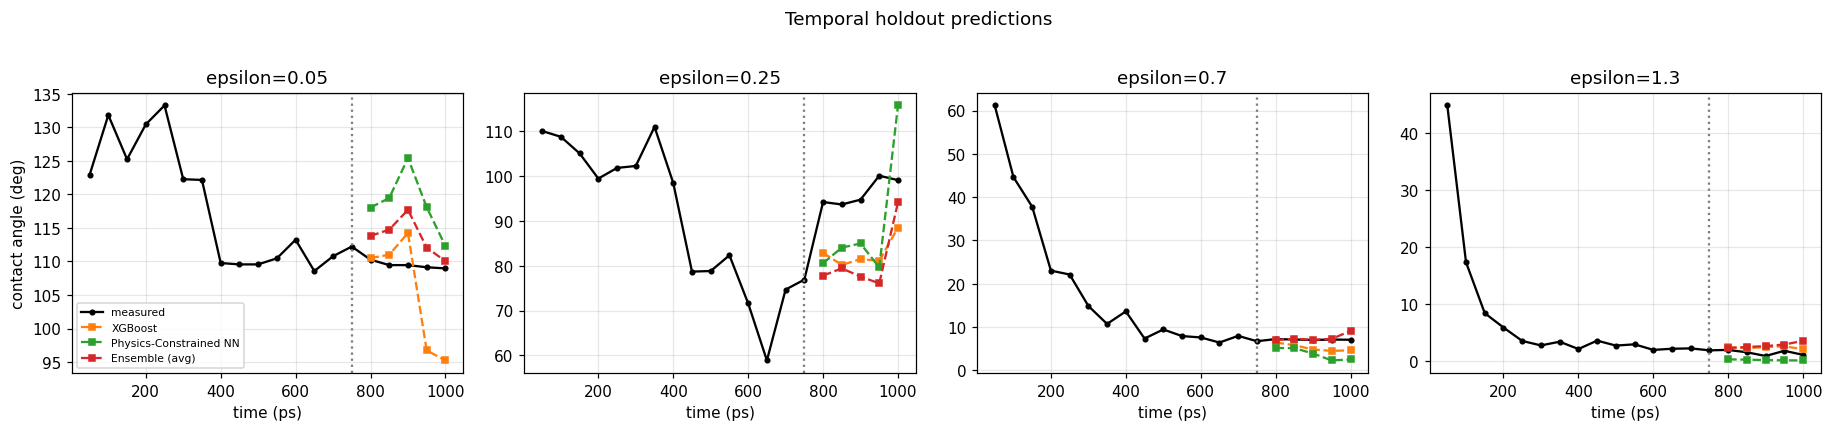

In [13]:
show = [best_A]
for extra in ["Physics-Constrained NN", "Ensemble (avg)"]:
    if extra in set(res_A["model"]) and extra not in show:
        show.append(extra)
eps_A = sorted(res_A["epsilon"].unique())
fig, axes = plt.subplots(1, len(eps_A), figsize=(4.2 * len(eps_A), 3.8), sharey=False)
axes = np.atleast_1d(axes)
for a, e in zip(axes, eps_A):
    g = df[(df["epsilon"] == e) & (~df["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    a.axvline(TRAIN_TMAX_PS, color="gray", ls=":")
    for k, name in enumerate(show):
        s = res_A[(res_A["model"] == name) & (res_A["epsilon"] == e)].sort_values("time_ps")
        a.plot(s["time_ps"], s["pred"], "--s", ms=4, color=cmap(k + 1), label=name)
    a.set_title(f"epsilon={e}")
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=7)
plt.suptitle("Temporal holdout predictions", y=1.02)
plt.tight_layout()
plt.show()

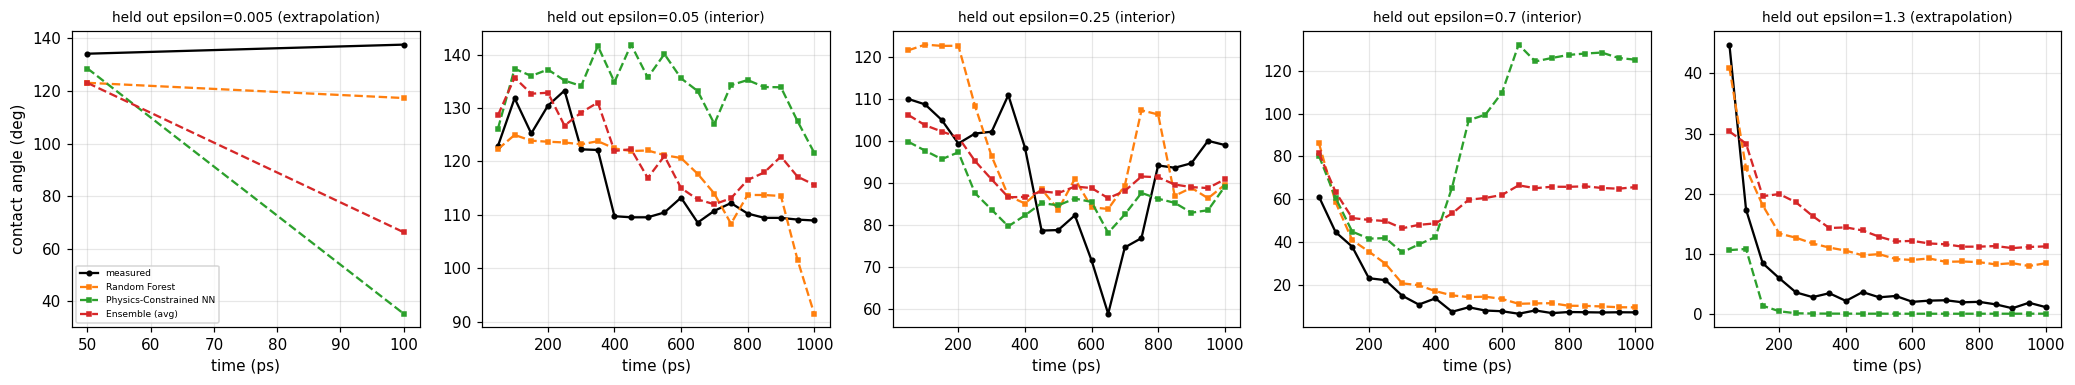

In [14]:
fig, axes = plt.subplots(1, len(EPS_LIST), figsize=(3.8 * len(EPS_LIST), 3.6))
for a, e in zip(axes, EPS_LIST):
    g = df[(df["epsilon"] == e) & (~df["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    for k, name in enumerate(dict.fromkeys([best_B, "Physics-Constrained NN", "Ensemble (avg)"])):
        s = res_B[(res_B["model"] == name) & (res_B["epsilon"] == e)].sort_values("time_ps")
        if len(s):
            a.plot(s["time_ps"], s["pred"], "--s", ms=3, color=cmap(k + 1), label=name)
    tag = "interior" if e in interior else "extrapolation"
    a.set_title(f"held out epsilon={e} ({tag})", fontsize=9)
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=6)
plt.tight_layout()
plt.show()

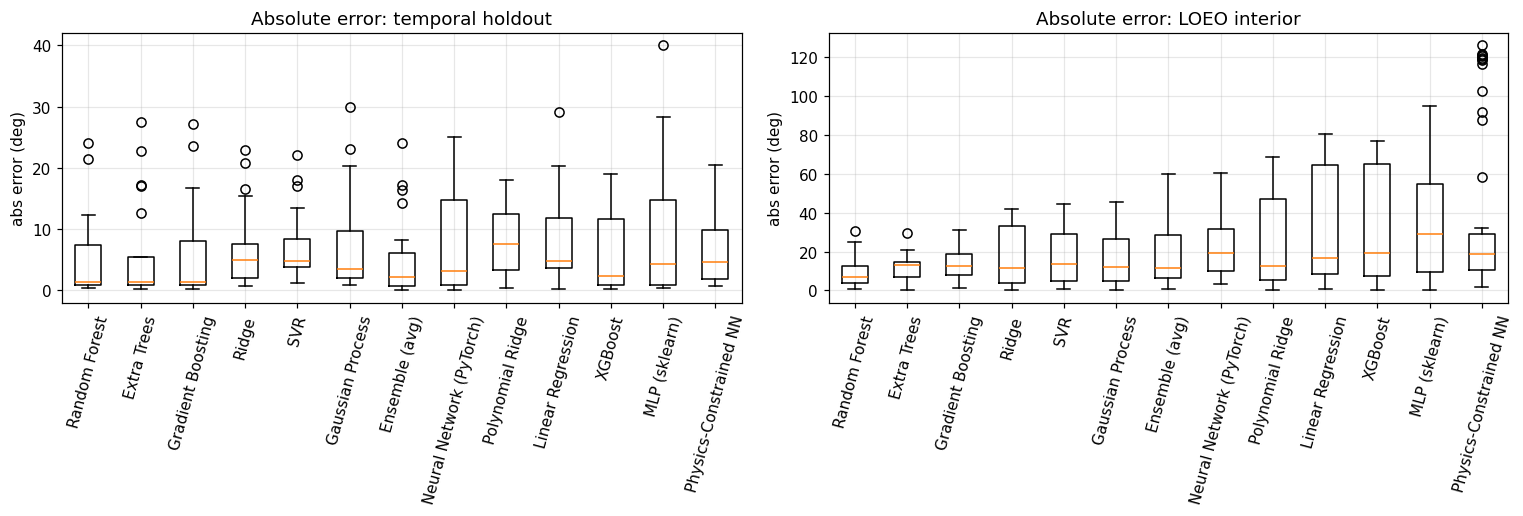

In [15]:
order = table_B_int["model"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ea = res_A.assign(err=(res_A["y"] - res_A["pred"]).abs())
eb = res_B[res_B["epsilon"].isin(interior)]
eb = eb.assign(err=(eb["y"] - eb["pred"]).abs())
for a, e_df, title in [(ax[0], ea, "Absolute error: temporal holdout"), (ax[1], eb, "Absolute error: LOEO interior")]:
    names = [m for m in order if m in set(e_df["model"])]
    a.boxplot([e_df[e_df["model"] == m]["err"].values for m in names], showfliers=True)
    a.set_xticklabels(names)
    a.set_title(title)
    a.set_ylabel("abs error (deg)")
    a.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

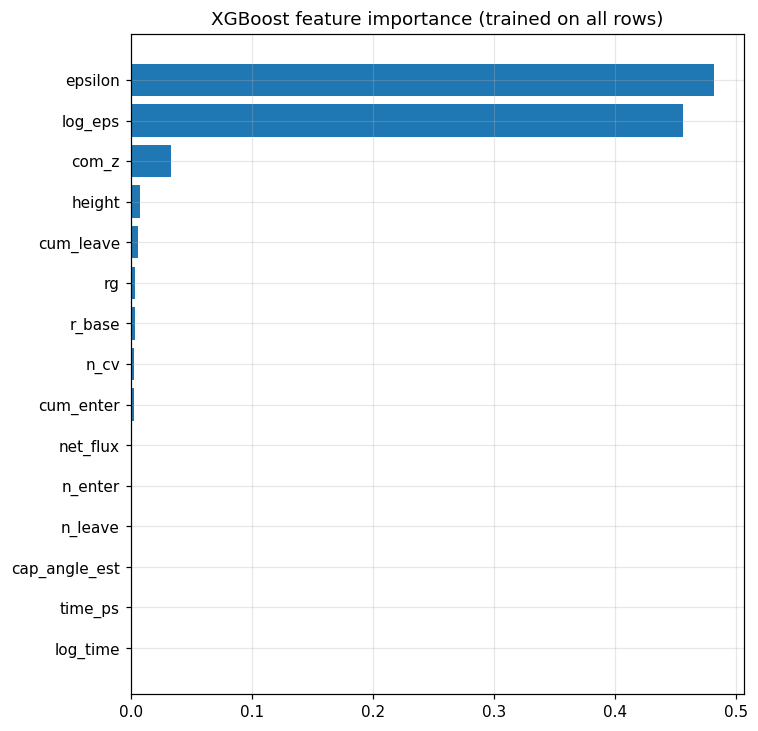

In [16]:
if USE_TRAJ and "XGBoost" in MODELS:
    xgb = clone(MODELS["XGBoost"]).fit(df[FEATURES].values, df[TARGET].values)
    imp = pd.Series(xgb.feature_importances_, index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1.5))
    ax.barh(imp.index, imp.values, color="tab:blue")
    ax.set_title("XGBoost feature importance (trained on all rows)")
    plt.tight_layout()
    plt.show()

## Final summary

In [17]:
final = pd.DataFrame({
    "temporal_RMSE": table_A.set_index("model")["RMSE"],
    "temporal_R2": table_A.set_index("model")["R2"],
    "LOEO_interior_RMSE": table_B_int.set_index("model")["RMSE"],
    "LOEO_interior_R2": table_B_int.set_index("model")["R2"],
    "LOEO_all_RMSE": table_B_all.set_index("model")["RMSE"],
}).sort_values("temporal_RMSE")
display(final.round(3))
final.to_csv(os.path.join(OUT_DIR, "final_summary.csv"))
print("features used:", FEATURES)
print("trajectory features used:", USE_TRAJ)
print("outputs saved to:", os.path.abspath(OUT_DIR))

,temporal_RMSE,temporal_R2,LOEO_interior_RMSE,LOEO_interior_R2,LOEO_all_RMSE
model,,,,,
XGBoost,8.219,0.973,43.111,0.064,37.443
Ensemble (avg),8.663,0.969,28.258,0.598,26.035
Random Forest,8.749,0.969,11.119,0.938,10.477
Physics-Constrained NN,9.075,0.966,51.770,-0.349,45.894
SVR,9.307,0.965,22.426,0.747,32.241
Ridge,9.556,0.963,22.192,0.752,20.305
Gradient Boosting,9.909,0.960,15.447,0.880,14.031
Polynomial Ridge,10.000,0.959,33.144,0.447,29.257
Extra Trees,10.128,0.958,12.978,0.915,11.870


features used: ['epsilon', 'log_eps', 'time_ps', 'log_time', 'n_cv', 'n_enter', 'n_leave', 'net_flux', 'cum_enter', 'cum_leave', 'com_z', 'height', 'r_base', 'rg', 'cap_angle_est']
trajectory features used: True
outputs saved to: /content/outputs
